## 단순한 계층 구현하기

계산 그래프의 곱셈 노드를 'MultiLayer', 덧셈 노드를 'AddLayer'로 구현

### 곱셈 계층


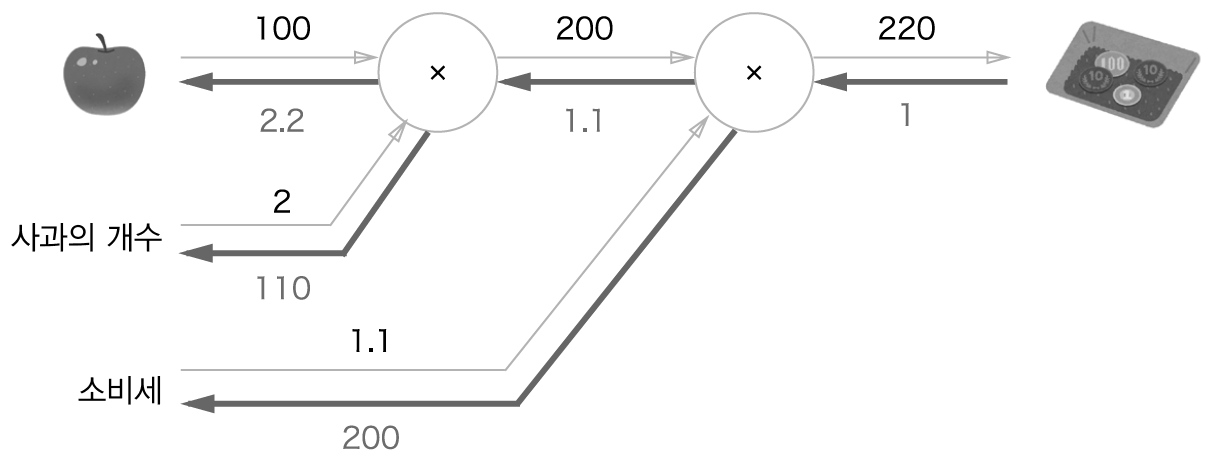

모든 계층은 forward() 순전파, backward() 역전파 라는 공통의 메서드(인터페이스)를 갖도록 수현

곱셈 계층을 MultiLayer 클래스로 다음처럼 구현

In [ ]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch05/layer_naive.py 소스 참고
class MulLayer:
    def __init__(self):
        self.x = None
        self.y = None

    def forward(self, x, y):
        self.x = x
        self.y = y
        out = x * y

        return out

    def backward(self, dout):
        dx = dout * self.y # x와 y를 바꾼다.
        dy = dout * self.x

        return dx, dy

\__init\__() : 인스턴스 변수인 x와 y를 초기화. 순전파 시 입력 값을 유지하기 위해 사용.

forward() : x와 y를 인수로 받고 두 값을 곱해 반환

backward() : 상류에서 넘어온 미분(dout)에 순전파 때 값을 '서로 바꿔' 곱한 후 하류로 흘림.

MultiLayer를 사용하여 순전파 구현

In [ ]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch05/buy_apple.py 소스 참고
apple = 100
apple_num = 2
tax = 1.1

# 계층들
mul_apple_layer = MulLayer()
mul_tax_layer = MulLayer()

# 순전파
apple_price = mul_apple_layer.forward(apple, apple_num)
price = mul_tax_layer.forward(apple_price, tax)

print(price) # 220

220.00000000000003


각 변수에 대한 미분은 backward()로 구할 수 있음

In [ ]:
dprice = 1
dapple_price, dtax = mul_tax_layer.backward(dprice)
dapple, dapple_num = mul_apple_layer.backward(dapple_price)

print(dapple, dapple_num, dtax) # 2.2 110 200

2.2 110.00000000000001 200


backward() 호출 순서는 forward() 때와 반대

backward()가 받는 인수는 '순전파의 출력에 대한 미분'

### 덧셈 계층

모든 계층은 forward() 순전파, backward() 역전파 라는 공통의 메서드(인터페이스)를 갖도록 수현

덧셈 계층을 MultiLayer 클래스

In [ ]:
class AddLayer:
    def __init__(self):
        pass

    def forward(self, x, y):
        out = x + y
        return out

    def backward(self, dout):
        dx = dout * 1
        dy = dout * 1
        return dx, dy

\__init\__() : pass를 통해 아무 일도 하지 않음

forward() : x와 y를 인수로 받고 두 값을 더해 반환

backward() : 상류에서 넘어온 미분(dout)을 그대로 하류로 흘림

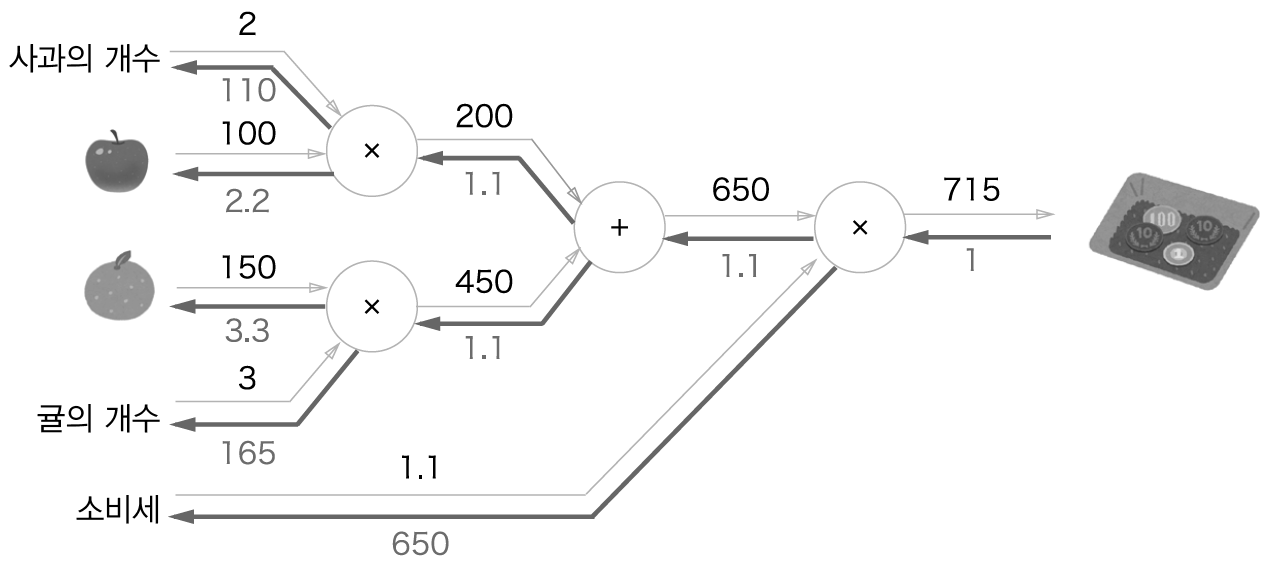

In [ ]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch05/buy_apple.py 소스 참고
apple = 100
apple_num = 2
orange = 150
orange_num = 3
tax = 1.1

# 계층들
mul_apple_layer = MulLayer()
mul_orange_layer = MulLayer()
add_apple_orange_layer = AddLayer()
mul_tax_layer = MulLayer()

# 순전파
apple_price = mul_apple_layer.forward(apple, apple_num)  # (1)
orange_price = mul_orange_layer.forward(orange, orange_num)  # (2)
all_price = add_apple_orange_layer.forward(apple_price, orange_price)  # (3)
price = mul_tax_layer.forward(all_price, tax)  # (4)

# 역전파
dprice = 1
dall_price, dtax = mul_tax_layer.backward(dprice)  # (4)
dapple_price, dorange_price = add_apple_orange_layer.backward(dall_price)  # (3)
dorange, dorange_num = mul_orange_layer.backward(dorange_price)  # (2)
dapple, dapple_num = mul_apple_layer.backward(dapple_price)  # (1)

print("price:", int(price)) # 715
print("dApple:", dapple) # 2.2
print("dApple_num:", int(dapple_num)) # 110
print("dOrange:", dorange) # 3.3
print("dOrange_num:", int(dorange_num)) # 165
print("dTax:", dtax) # 650

price: 715
dApple: 2.2
dApple_num: 110
dOrange: 3.3000000000000003
dOrange_num: 165
dTax: 650


### ReLU 계층


In [ ]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/common/layers.py 소스 참고
class Relu:
    def __init__(self):
        self.mask = None

    def forward(self, x):
        self.mask = (x <= 0)
        out = x.copy()
        out[self.mask] = 0

        return out

    def backward(self, dout):
        dout[self.mask] = 0
        dx = dout

        return dx

Relu 클래스는 mask 인스턴스 변수를 가짐

mask는 순전파의 입력인 x의 원소 값이 0 이하인 인덱스는 True, 그 외(0보다 큰 원소)는 False로 유지

In [ ]:
import numpy as np
x = np.array([[1.0, 0.5], [-2.0, 3.0]])
print(x)

[[ 1.   0.5]
 [-2.   3. ]]


In [ ]:
mask = (x <= 0)
print(mask)

[[False False]
 [ True False]]


In [ ]:
out = x.copy()
out[mask] = 0
out

array([[1. , 0.5],
       [0. , 3. ]])

ReLU 계층은 전기 회로의 '스위치'에 비유

순전파 때 전류가 흐르고 있으면 스위치를 ON, 흐르지 않으면 OFF

역전파 때 스위치가 ON이라면 전류가 그대로 흐르고, OFF면 더 이상 흐르지 않음

### Sigmoid 계층


In [ ]:
class Sigmoid:
    def __init__(self):
        self.out = None

    def forward(self, x):
        out = 1 / (1 + np.exp(-x))
        self.out = out

        return out

    def backward(self, dout):
        dx = dout * (1.0 - self.out) * self.out

        return dx

## Affine 계층

신경망의 순전파에서는 가중치 신호의 총합을 계산하기 위해 행렬의 내적(np.dot())을 사용

In [ ]:
X = np.random.rand(2)   # 입력
W = np.random.rand(2,3) # 가중치
B = np.random.rand(3)   # 편향

print(X.shape) # (2,)
print(W.shape) # (2, 3)
print(B.shape) # (3,)

Y = np.dot(X, W) + B

(2,)
(2, 3)
(3,)


### 배치용 Affine 계층

기존과 다른 부분은 입력인 X의 형상이 (N,2)가 됨

예를 들어 N=2(데이터가 2개)로 한 경우, 편향은 그 두 데이터 각각에 더해집니다.

In [ ]:
X_dot_W = np.array([[0, 0, 0], [10, 10, 10]])
B = np.array([1, 2, 3])

X_dot_W

array([[ 0,  0,  0],
       [10, 10, 10]])

In [ ]:
X_dot_W + B
print(X_dot_W.shape)

(2, 3)


순전파의 편향 덧셈은 각각의 데이터(1번째 데이터, 2번째 데이터)에 더해짐

역전파 때는 각 데이터의 역전파 값이 편향의 원소에 모여야 함

In [ ]:
dY = np.array([[1, 2, 3], [4, 5, 6]])
dY

array([[1, 2, 3],
       [4, 5, 6]])

In [ ]:
dB = np.sum(dY, axis=0)
dB

array([5, 7, 9])

np.sum()에서 0번째 축(데이터를 단위로 한 축)에 대해서 (axis=0)의 총합을 구함

Affine 구현



In [ ]:
class Affine:
    def __init__(self, W, b):
        self.W = W
        self.b = b
        self.x = None
        self.dW = None
        self.db = None

    def forward(self, x):
        self.x = x
        out = np.dot(x, self.W) + self.b

        return out

    def backward(self, dout):
        dx = np.dot(dout, self.W.T)
        self.dW = np.dot(self.x.T, dout)
        self.db = np.sum(dout, axis=0)

        return dx

### Softmax-with-Loss 계층



In [ ]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/common/functions.py 소스 참고
# 3.5.2 소프트맥스 함수 구현시 주의점 참고
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# 4.2.2. 교차 엔트로피 오차 참고
def cross_entropy_error(y, t):
    if y.ndim == 1:
        t = t.reshape(1, t.size)
        y = y.reshape(1, y.size)

    # 훈련 데이터가 원-핫 벡터라면 정답 레이블의 인덱스로 반환
    if t.size == y.size:
        t = t.argmax(axis=1)

    batch_size = y.shape[0]
    return -np.sum(np.log(y[np.arange(batch_size), t])) / batch_size

class SoftmaxWithLoss:
    def __init__(self):
        self.loss = None # 손실
        self.y = None    # softmax의 출력
        self.t = None    # 정답 레이블(원-핫 벡터)

    def forward(self, x, t):
        self.t = t
        self.y = softmax(x)
        self.loss = cross_entropy_error(self.y, self.t)
        return self.loss

    def backward(self, dout=1):
        batch_size = self.t.shape[0]
        dx = (self.y - self.t) / batch_size

        return dx

주의. 역전파 때는 전파하는 값을 배치의 수(batch_size)로 나눠 데이터 1개당 오차를 앞 계층으로 전파함

## 오차역전파법 구현하기

In [ ]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch05/two_layer_net.py 참고
# coding: utf-8
#import sys, os
#sys.path.append(os.pardir)  # 부모 디렉터리의 파일을 가져올 수 있도록 설정
import numpy as np
#from common.layers import *
#from common.gradient import numerical_gradient
from collections import OrderedDict

# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/common/functions.py
def softmax(x):
    if x.ndim == 2:
        x = x.T
        x = x - np.max(x, axis=0)
        y = np.exp(x) / np.sum(np.exp(x), axis=0)
        return y.T

    x = x - np.max(x) # 오버플로 대책
    return np.exp(x) / np.sum(np.exp(x))

# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/common/gradient.py 참고
def numerical_gradient(f, x):
    h = 1e-4 # 0.0001
    grad = np.zeros_like(x)

    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        idx = it.multi_index
        tmp_val = x[idx]
        x[idx] = float(tmp_val) + h
        fxh1 = f(x) # f(x+h)

        x[idx] = tmp_val - h
        fxh2 = f(x) # f(x-h)
        grad[idx] = (fxh1 - fxh2) / (2*h)

        x[idx] = tmp_val # 값 복원
        it.iternext()

    return grad


class TwoLayerNet:

    def __init__(self, input_size, hidden_size, output_size, weight_init_std = 0.01):
        # 가중치 초기화
        self.params = {}
        self.params['W1'] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)

        # 계층 생성
        self.layers = OrderedDict()                                           ###
        self.layers['Affine1'] = Affine(self.params['W1'], self.params['b1']) ###
        self.layers['Relu1'] = Relu()                                         ###
        self.layers['Affine2'] = Affine(self.params['W2'], self.params['b2']) ###

        self.lastLayer = SoftmaxWithLoss()                                    ###

    def predict(self, x):
        for layer in self.layers.values():                                    ###
            x = layer.forward(x)                                              ###

        return x

    # x : 입력 데이터, t : 정답 레이블
    def loss(self, x, t):
        y = self.predict(x)
        return self.lastLayer.forward(y, t)

    def accuracy(self, x, t):
        y = self.predict(x)
        y = np.argmax(y, axis=1)
        if t.ndim != 1 : t = np.argmax(t, axis=1)

        accuracy = np.sum(y == t) / float(x.shape[0])
        return accuracy

    # x : 입력 데이터, t : 정답 레이블
    def numerical_gradient(self, x, t):
        loss_W = lambda W: self.loss(x, t)

        grads = {}
        grads['W1'] = numerical_gradient(loss_W, self.params['W1'])
        grads['b1'] = numerical_gradient(loss_W, self.params['b1'])
        grads['W2'] = numerical_gradient(loss_W, self.params['W2'])
        grads['b2'] = numerical_gradient(loss_W, self.params['b2'])

        return grads

    def gradient(self, x, t):
        # forward
        self.loss(x, t)                      ###

        # backward
        dout = 1                             ###
        dout = self.lastLayer.backward(dout) ###

        layers = list(self.layers.values())  ###
        layers.reverse()                     ###
        for layer in layers:                 ###
            dout = layer.backward(dout)      ###

        # 결과 저장
        grads = {}
        grads['W1'], grads['b1'] = self.layers['Affine1'].dW, self.layers['Affine1'].db
        grads['W2'], grads['b2'] = self.layers['Affine2'].dW, self.layers['Affine2'].db

        return grads

\### 으로 중요코드 표시. 집중해서 살펴보세요.

OrderedDict: 딕셔너리에 추가한 순서를 기억하는 (순서가 있는) 딕셔너리

순전파 때는 추가한 순서대로 각 계층의 forward() 메서드를 호출

역전파 때는 계층을 반대 순서로 호출

신경망의 구성 요소를 '계층'으로 구현한 덕분에 신경망을 쉽게 구축

=> 레고 블록을 조립하듯 필요한 만큼 계층을 더 추가하면 됨

### 오차역전파법으로 구한 기울기 검증하기
아래 사이트에서 4개 파일을 다운받고 colab에 업로드


https://github.com/jhahncs/Class-Artificial-Intelligence/tree/Fall-2026/dataset

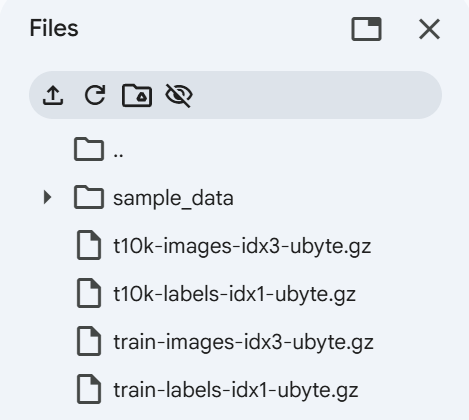

In [ ]:
# coding: utf-8
try:
    import urllib.request
except ImportError:
    raise ImportError('You should use Python 3.x')
import os.path
import gzip
import pickle
import os
import numpy as np


key_file = {
    'train_img':'train-images-idx3-ubyte.gz',
    'train_label':'train-labels-idx1-ubyte.gz',
    'test_img':'t10k-images-idx3-ubyte.gz',
    'test_label':'t10k-labels-idx1-ubyte.gz'
}

dataset_dir = "/content"
save_file = dataset_dir + "/mnist.pkl"

train_num = 60000
test_num = 10000
img_dim = (1, 28, 28)
img_size = 784



def _load_label(file_name):
    file_path = dataset_dir + "/" + file_name

    print("Converting " + file_name + " to NumPy Array ...")
    with gzip.open(file_path, 'rb') as f:
            labels = np.frombuffer(f.read(), np.uint8, offset=8)
    print("Done")

    return labels

def _load_img(file_name):
    file_path = dataset_dir + "/" + file_name

    print("Converting " + file_name + " to NumPy Array ...")
    with gzip.open(file_path, 'rb') as f:
            data = np.frombuffer(f.read(), np.uint8, offset=16)
    data = data.reshape(-1, img_size)
    print("Done")

    return data

def _convert_numpy():
    dataset = {}
    dataset['train_img'] =  _load_img(key_file['train_img'])
    dataset['train_label'] = _load_label(key_file['train_label'])
    dataset['test_img'] = _load_img(key_file['test_img'])
    dataset['test_label'] = _load_label(key_file['test_label'])

    return dataset

def init_mnist():
    download_mnist()
    dataset = _convert_numpy()
    print("Creating pickle file ...")
    with open(save_file, 'wb') as f:
        pickle.dump(dataset, f, -1)
    print("Done!")

def _change_one_hot_label(X):
    T = np.zeros((X.size, 10))
    for idx, row in enumerate(T):
        row[X[idx]] = 1

    return T


def load_mnist(normalize=True, flatten=True, one_hot_label=False):
    """MNIST 데이터셋 읽기

    Parameters
    ----------
    normalize : 이미지의 픽셀 값을 0.0~1.0 사이의 값으로 정규화할지 정한다.
    one_hot_label :
        one_hot_label이 True면、레이블을 원-핫(one-hot) 배열로 돌려준다.
        one-hot 배열은 예를 들어 [0,0,1,0,0,0,0,0,0,0]처럼 한 원소만 1인 배열이다.
    flatten : 입력 이미지를 1차원 배열로 만들지를 정한다.

    Returns
    -------
    (훈련 이미지, 훈련 레이블), (시험 이미지, 시험 레이블)
    """
    if not os.path.exists(save_file):
        init_mnist()

    with open(save_file, 'rb') as f:
        dataset = pickle.load(f)

    if normalize:
        for key in ('train_img', 'test_img'):
            dataset[key] = dataset[key].astype(np.float32)
            dataset[key] /= 255.0

    if one_hot_label:
        dataset['train_label'] = _change_one_hot_label(dataset['train_label'])
        dataset['test_label'] = _change_one_hot_label(dataset['test_label'])

    if not flatten:
         for key in ('train_img', 'test_img'):
            dataset[key] = dataset[key].reshape(-1, 1, 28, 28)

    return (dataset['train_img'], dataset['train_label']), (dataset['test_img'], dataset['test_label'])


if __name__ == '__main__':
    init_mnist()


Done
Done
Done
Done
Converting train-images-idx3-ubyte.gz to NumPy Array ...
Done
Converting train-labels-idx1-ubyte.gz to NumPy Array ...
Done
Converting t10k-images-idx3-ubyte.gz to NumPy Array ...
Done
Converting t10k-labels-idx1-ubyte.gz to NumPy Array ...
Done
Creating pickle file ...
Done!


In [ ]:
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)
network = TwoLayerNet(input_size=784, hidden_size=50, output_size=10)
x_batch = x_train[:3]
t_batch = t_train[:3]

In [ ]:
%timeit network.numerical_gradient(x_batch, t_batch)

1 loop, best of 5: 8.35 s per loop


In [ ]:
%timeit network.gradient(x_batch, t_batch)

1000 loops, best of 5: 301 µs per loop


수치미분(numerical_gradient) 속도: 9.95초

오차역전법(gradient) 속도: 248 µs, 0.000248초

약 42,000배 속도차이가 남

수치 미분을 오차역전파법을 정확히 구현했는지 확인하기 위해 필요.

수치 미분의 이점은 구현하기 쉬움

기울기 확인(gradient check): 수치 미분의 결과와 오차역전파법의 결과를 비교하여 오차역전파법을 제대로 구현했는지 검증함.

In [ ]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch05/gradient_check.py 참고
# coding: utf-8
#import sys, os
#sys.path.append(os.pardir)  # 부모 디렉터리의 파일을 가져올 수 있도록 설정
import numpy as np

# 데이터 읽기
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)

network = TwoLayerNet(input_size=784, hidden_size=50, output_size=10)

x_batch = x_train[:3]
t_batch = t_train[:3]

grad_numerical = network.numerical_gradient(x_batch, t_batch)
grad_backprop = network.gradient(x_batch, t_batch)

# 각 가중치의 절대 오차의 평균을 구한다.
for key in grad_numerical.keys():
    diff = np.average( np.abs(grad_backprop[key] - grad_numerical[key]) )
    print(key + ":" + str(diff))

W1:2.6280316977901613e-13
b1:1.077377501990974e-12
W2:9.783228291406475e-13
b2:1.2034818003270332e-10


이 결과는 수치 미분과 오차역전파법으로 구한 기울기의 차이가 매우 작다고 말해줌

오차역전법이 실수 없이 구현했다는 믿음이 커짐

수치 미분과 오차역전파법의 결과 오차가 0이 되는 일은 드뭄

올바르게 구현했다면 0에 아주 가까운 작은 값이 됨

### 오차역전파법을 사용한 학습 구현하기

In [ ]:
# coding: utf-8
#import sys, os
#sys.path.append(os.pardir)
import numpy as np
#from two_layer_net import TwoLayerNet

# 데이터 읽기
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)

network = TwoLayerNet(input_size=784, hidden_size=50, output_size=10)

iters_num = 10000
train_size = x_train.shape[0]
batch_size = 100
learning_rate = 0.1

train_loss_list = []
train_acc_list = []
test_acc_list = []

iter_per_epoch = max(train_size / batch_size, 1)

for i in range(iters_num):
    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    # 기울기 계산
    #grad = network.numerical_gradient(x_batch, t_batch) # 수치 미분 방식
    grad = network.gradient(x_batch, t_batch) # 오차역전파법 방식(훨씬 빠르다)

    # 갱신
    for key in ('W1', 'b1', 'W2', 'b2'):
        network.params[key] -= learning_rate * grad[key]

    loss = network.loss(x_batch, t_batch)
    train_loss_list.append(loss)

    if i % iter_per_epoch == 0:
        train_acc = network.accuracy(x_train, t_train)
        test_acc = network.accuracy(x_test, t_test)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)
        print(train_acc, test_acc)

0.10543333333333334 0.1044
0.90385 0.9051
0.92425 0.9266
0.9349 0.9365
0.94405 0.9437
0.9495666666666667 0.9496
0.9559 0.9532
0.96035 0.9557
0.9638166666666667 0.9613
0.9655333333333334 0.9611
0.96885 0.9642
0.9719333333333333 0.9671
0.9731 0.9673
0.9751166666666666 0.9677
0.97625 0.9685
0.9776 0.9692
0.9782666666666666 0.9687


**이번 장에서 배운 것**

계산그래프를 이용하면 계산 과정을 시각적으로 파악 가능

계산그래프 노드는 국소적 계산으로 구성. 국소적 계산을 조합해 전체 계산을 구성

순전파는 통상의 계산을 수행. 역전파는 노드의 미분을 구함

오차역전파법: 신경망의 구성 요소를 계층으로 구현하여 기울기를 효율적으로 계산

기울기 확인: 수치 미분과 오차역전파법의 결과를 비교하면 오차역전파법 구현에 잘못이 없는지 확인가능

In [ ]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch05/two_layer_net.py 참고
# coding: utf-8
#import sys, os
#sys.path.append(os.pardir)  # 부모 디렉터리의 파일을 가져올 수 있도록 설정
import numpy as np
#from common.layers import *
#from common.gradient import numerical_gradient
from collections import OrderedDict

# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/common/functions.py
def softmax(x):
    if x.ndim == 2:
        x = x.T
        x = x - np.max(x, axis=0)
        y = np.exp(x) / np.sum(np.exp(x), axis=0)
        return y.T

    x = x - np.max(x) # 오버플로 대책
    return np.exp(x) / np.sum(np.exp(x))

# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/common/gradient.py 참고
def numerical_gradient(f, x):
    h = 1e-4 # 0.0001
    grad = np.zeros_like(x)

    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        idx = it.multi_index
        tmp_val = x[idx]
        x[idx] = float(tmp_val) + h
        fxh1 = f(x) # f(x+h)

        x[idx] = tmp_val - h
        fxh2 = f(x) # f(x-h)
        grad[idx] = (fxh1 - fxh2) / (2*h)

        x[idx] = tmp_val # 값 복원
        it.iternext()

    return grad


class TwoLayerNet:

    def __init__(self, input_size, hidden_size, output_size, weight_init_std = 0.01):
        # 가중치 초기화
        self.params = {}
        self.params['W1'] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)

        # 계층 생성
        self.layers = OrderedDict()                                           ###
        self.layers['Affine1'] = Affine(self.params['W1'], self.params['b1']) ###
        self.layers['Relu1'] = Relu()                                         ###
        self.layers['Affine2'] = Affine(self.params['W2'], self.params['b2']) ###

        self.lastLayer = SoftmaxWithLoss()                                    ###

    def predict(self, x):
        for layer in self.layers.values():                                    ###
            x = layer.forward(x)                                              ###

        return x

    # x : 입력 데이터, t : 정답 레이블
    def loss(self, x, t):
        y = self.predict(x)
        return self.lastLayer.forward(y, t)

    def accuracy(self, x, t):
        y = self.predict(x)
        y = np.argmax(y, axis=1)
        if t.ndim != 1 : t = np.argmax(t, axis=1)

        accuracy = np.sum(y == t) / float(x.shape[0])
        return accuracy

    # x : 입력 데이터, t : 정답 레이블
    def numerical_gradient(self, x, t):
        loss_W = lambda W: self.loss(x, t)

        grads = {}
        grads['W1'] = numerical_gradient(loss_W, self.params['W1'])
        grads['b1'] = numerical_gradient(loss_W, self.params['b1'])
        grads['W2'] = numerical_gradient(loss_W, self.params['W2'])
        grads['b2'] = numerical_gradient(loss_W, self.params['b2'])

        return grads

    def gradient(self, x, t):
        # forward
        self.loss(x, t)                      ###

        # backward
        dout = 1                             ###
        dout = self.lastLayer.backward(dout) ###

        layers = list(self.layers.values())  ###
        layers.reverse()                     ###
        for layer in layers:                 ###
            dout = layer.backward(dout)      ###

        # 결과 저장
        grads = {}
        grads['W1'], grads['b1'] = self.layers['Affine1'].dW, self.layers['Affine1'].db
        grads['W2'], grads['b2'] = self.layers['Affine2'].dW, self.layers['Affine2'].db

        return grads